In [ ]:
%pip install -r requirements.txt

## Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn

## Data Uploading

In [5]:
train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")

## Exploration

In [12]:
print("size of training", train_df.shape)
train_df.head()

size of training (60000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [13]:
print("size of training", test_df.shape)
test_df.head()

size of training (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
# Missing or null values
print("\nNull values in training: ", train_df.isnull().sum().sum())
print("Null values in test: ", test_df.isnull().sum().sum())


Null values in training:  0
Null values in test:  0


In [15]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

train_dist = train_df["label"].value_counts().sort_index().rename(index=class_names)
test_dist = test_df["label"].value_counts().sort_index().rename(index=class_names)

class_summary = pd.DataFrame({
    "Train Count": train_dist,
    "Train (%)": (train_dist / len(train_df) * 100).round(2),
    "Test Count": test_dist,
    "Test (%)": (test_dist / len(test_df) * 100).round(2)
})

display(class_summary)

,Train Count,Train (%),Test Count,Test (%)
label,,,,
T-shirt/top,6000,10.0,1000,10.0
Trouser,6000,10.0,1000,10.0
Pullover,6000,10.0,1000,10.0
Dress,6000,10.0,1000,10.0
Coat,6000,10.0,1000,10.0
Sandal,6000,10.0,1000,10.0
Shirt,6000,10.0,1000,10.0
Sneaker,6000,10.0,1000,10.0
Bag,6000,10.0,1000,10.0


## Visualization

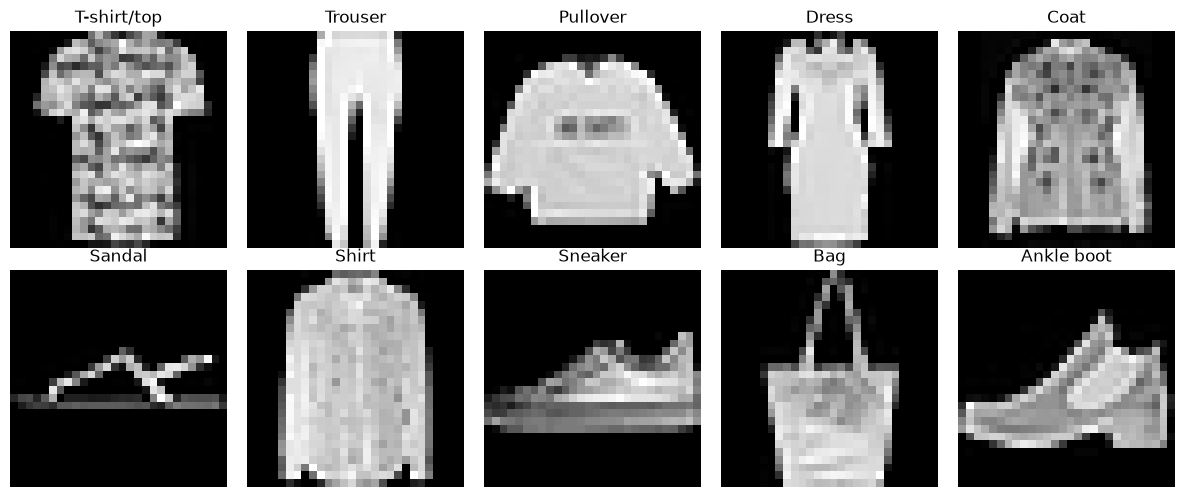

In [16]:
# Plot one sample image for each of the 10 clothing categories
plt.figure(figsize=(12, 5))

for label_id, class_name in class_names.items():
    sample_row = train_df[train_df["label"] == label_id].iloc[0]
    
    # Extract the 784 pixel values and reshape into a 28x28 image
    image_2d = sample_row.drop("label").values.reshape(28, 28)
    
    plt.subplot(2, 5, label_id + 1)
    plt.imshow(image_2d, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()